نصب کتابخانه‌ها

In [3]:
!pip install xgboost lightgbm catboost
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

print("کتابخانه‌ها با موفقیت نصب و بارگذاری شدند.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.5 MB/s eta 0:00:00
کتابخانه‌ها با موفقیت نصب و بارگذاری شدند.


وارد کردن کتابخانه‌ها

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, ElasticNet, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
import tensorflow as tf
from google.colab import files

بارگذاری داده‌ها

Upload your X.txt and Y.txt files


Saving X.txt to X.txt
Saving Y.txt to Y.txt
Input shape: (336, 5), Output shape: (336, 1)


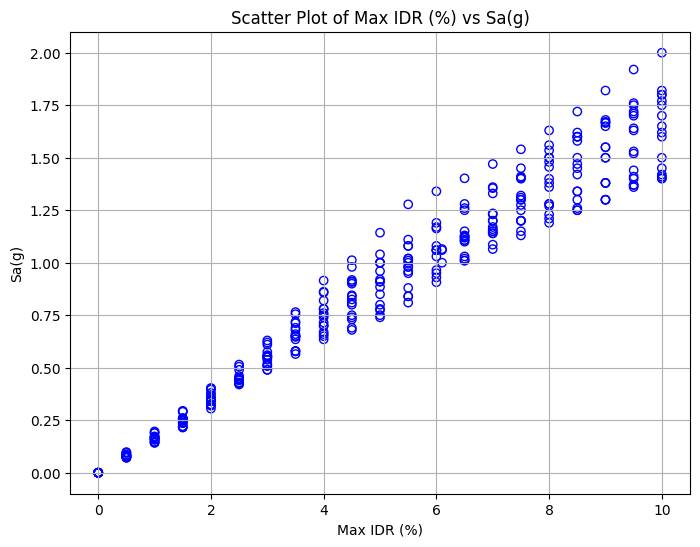

In [5]:
print("Upload your X.txt and Y.txt files")
uploaded = files.upload()
X = np.loadtxt('X.txt')
y = np.loadtxt('Y.txt')
if y.ndim == 1:
    y = y.reshape(-1, 1)
print(f"Input shape: {X.shape}, Output shape: {y.shape}")
def clip_inputs(X):
    X_clipped = X.copy()
    X_clipped[:, 0] = np.clip(X_clipped[:, 0], 235, 350)   # مقاومت تسلیم فولاد
    X_clipped[:, 3] = np.clip(X_clipped[:, 3], 800, 1200)  # بار زنده سقف
    return X_clipped
X = clip_inputs(X)

#---------------------------------------------------------------------------------------------------------------------------------------------
x_values = y.ravel()        # محور افقی: داده‌های Y (Max IDR (%))
y_values = X[:, 4]          # محور عمودی: ستون پنجم X (Sa(g))

plt.figure(figsize=(8,6))
plt.scatter(x_values, y_values, marker='o', facecolors='none', edgecolors='b')
plt.title('Scatter Plot of Max IDR (%) vs Sa(g)')
plt.xlabel('Max IDR (%)')   # عنوان محور افقی
plt.ylabel('Sa(g)')         # عنوان محور عمودی
plt.grid(True)
plt.show()

تقسیم داده‌ها به آموزش، اعتبارسنجی و آزمون

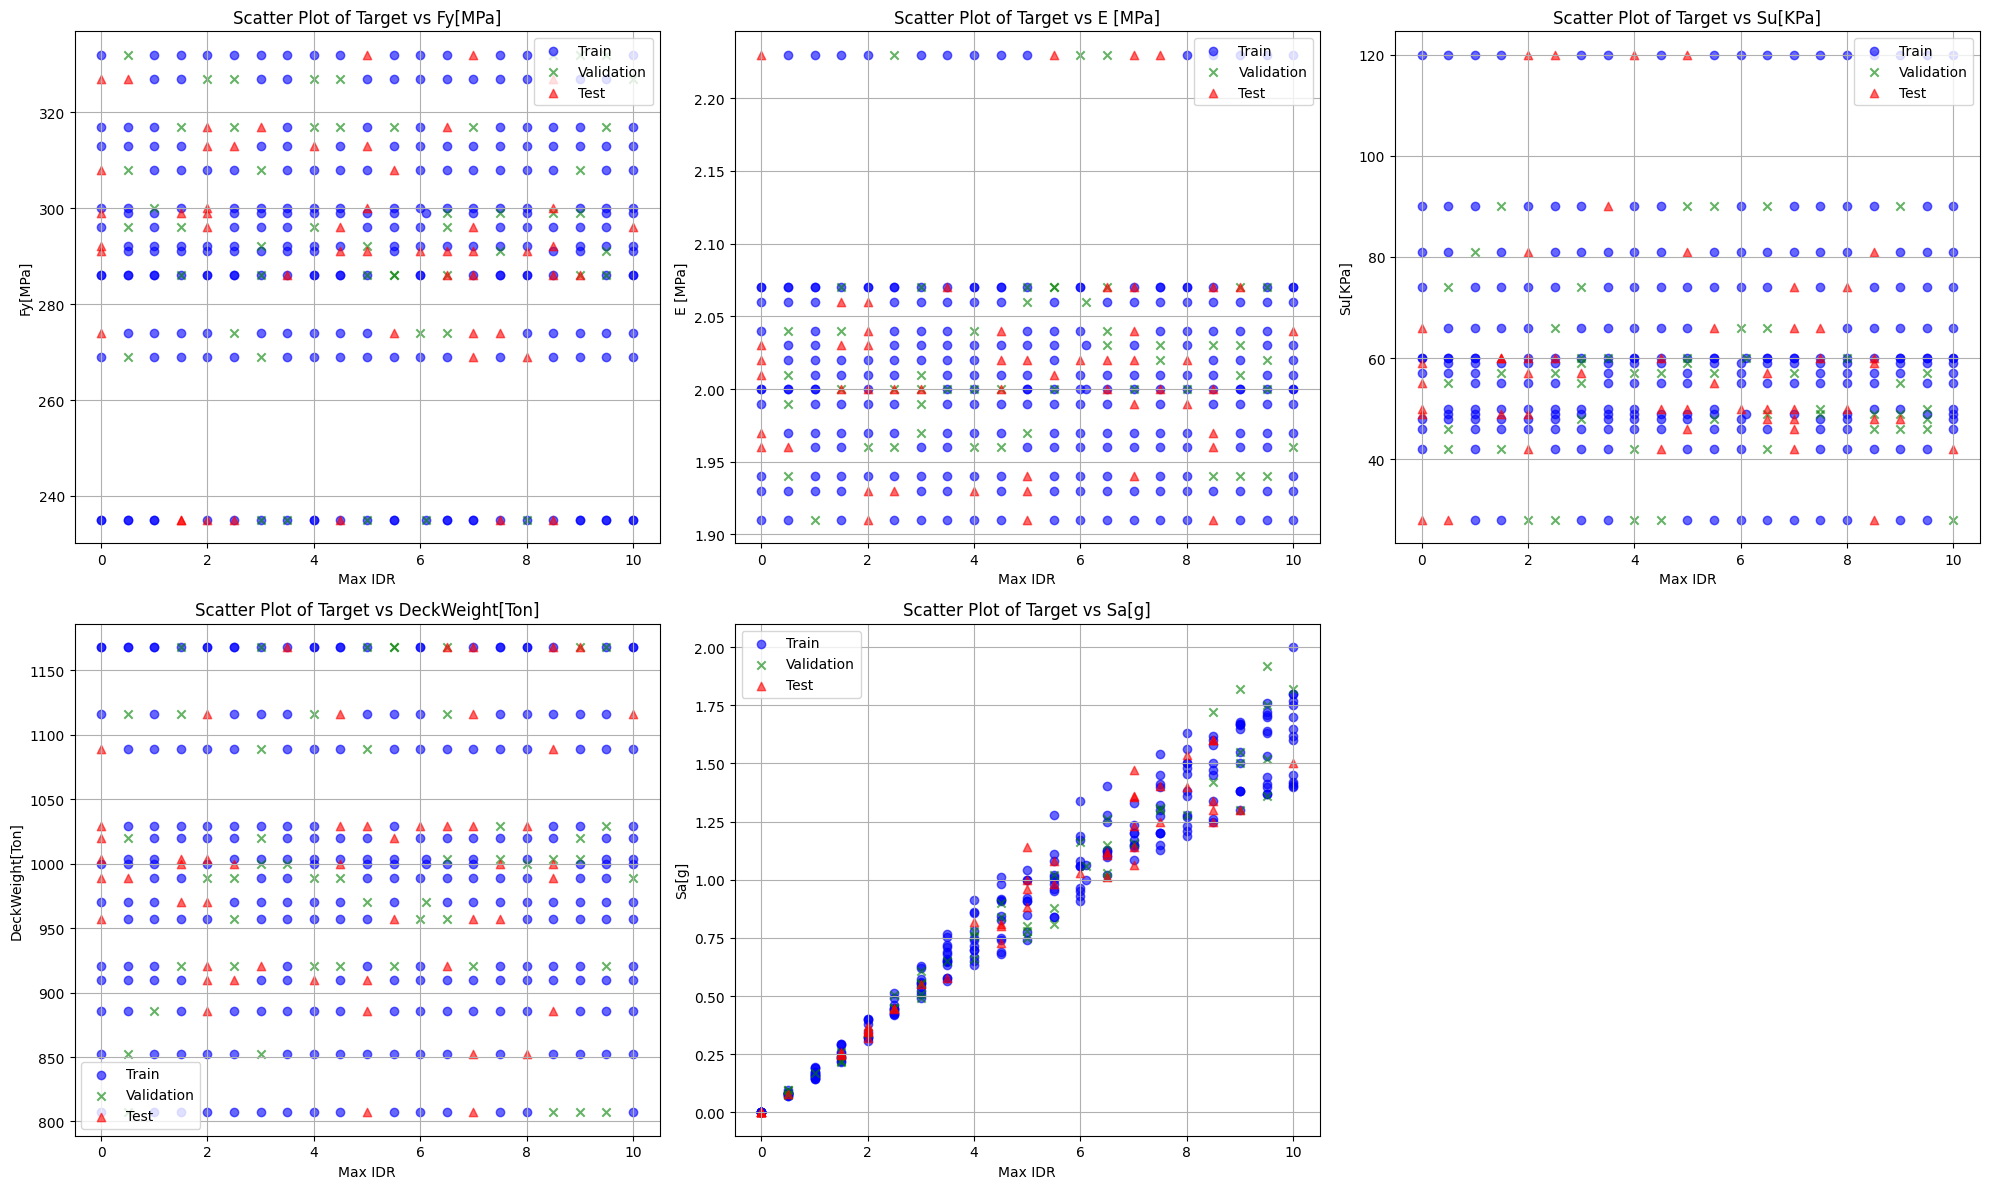

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)


# X_train_full, X_val, X_test, y_train_full, y_val, y_test

# نام ستون‌های ورودی برای عنوان نمودارها
feature_names = ['Fy[MPa]', 'E [MPa]', 'Su[KPa]', 'DeckWeight[Ton]', 'Sa[g]']


colors = {
    'Train': 'blue',
    'Validation': 'green',
    'Test': 'red'
}
markers = {
    'Train': 'o',
    'Validation': 'x',
    'Test': '^'
}

# رسم 5 نمودار جداگانه برای هر ستون ورودی
plt.figure(figsize=(20, 12))

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.scatter(y_train.ravel(), X_train[:, i], color=colors['Train'], marker=markers['Train'], label='Train', alpha=0.6)
    plt.scatter(y_val.ravel(), X_val[:, i], color=colors['Validation'], marker=markers['Validation'], label='Validation', alpha=0.6)
    plt.scatter(y_test.ravel(), X_test[:, i], color=colors['Test'], marker=markers['Test'], label='Test', alpha=0.6)
    plt.xlabel('Max IDR')
    plt.ylabel(feature_names[i])
    plt.title(f'Scatter Plot of Target vs {feature_names[i]}')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()


نرمال‌سازی داده‌ها

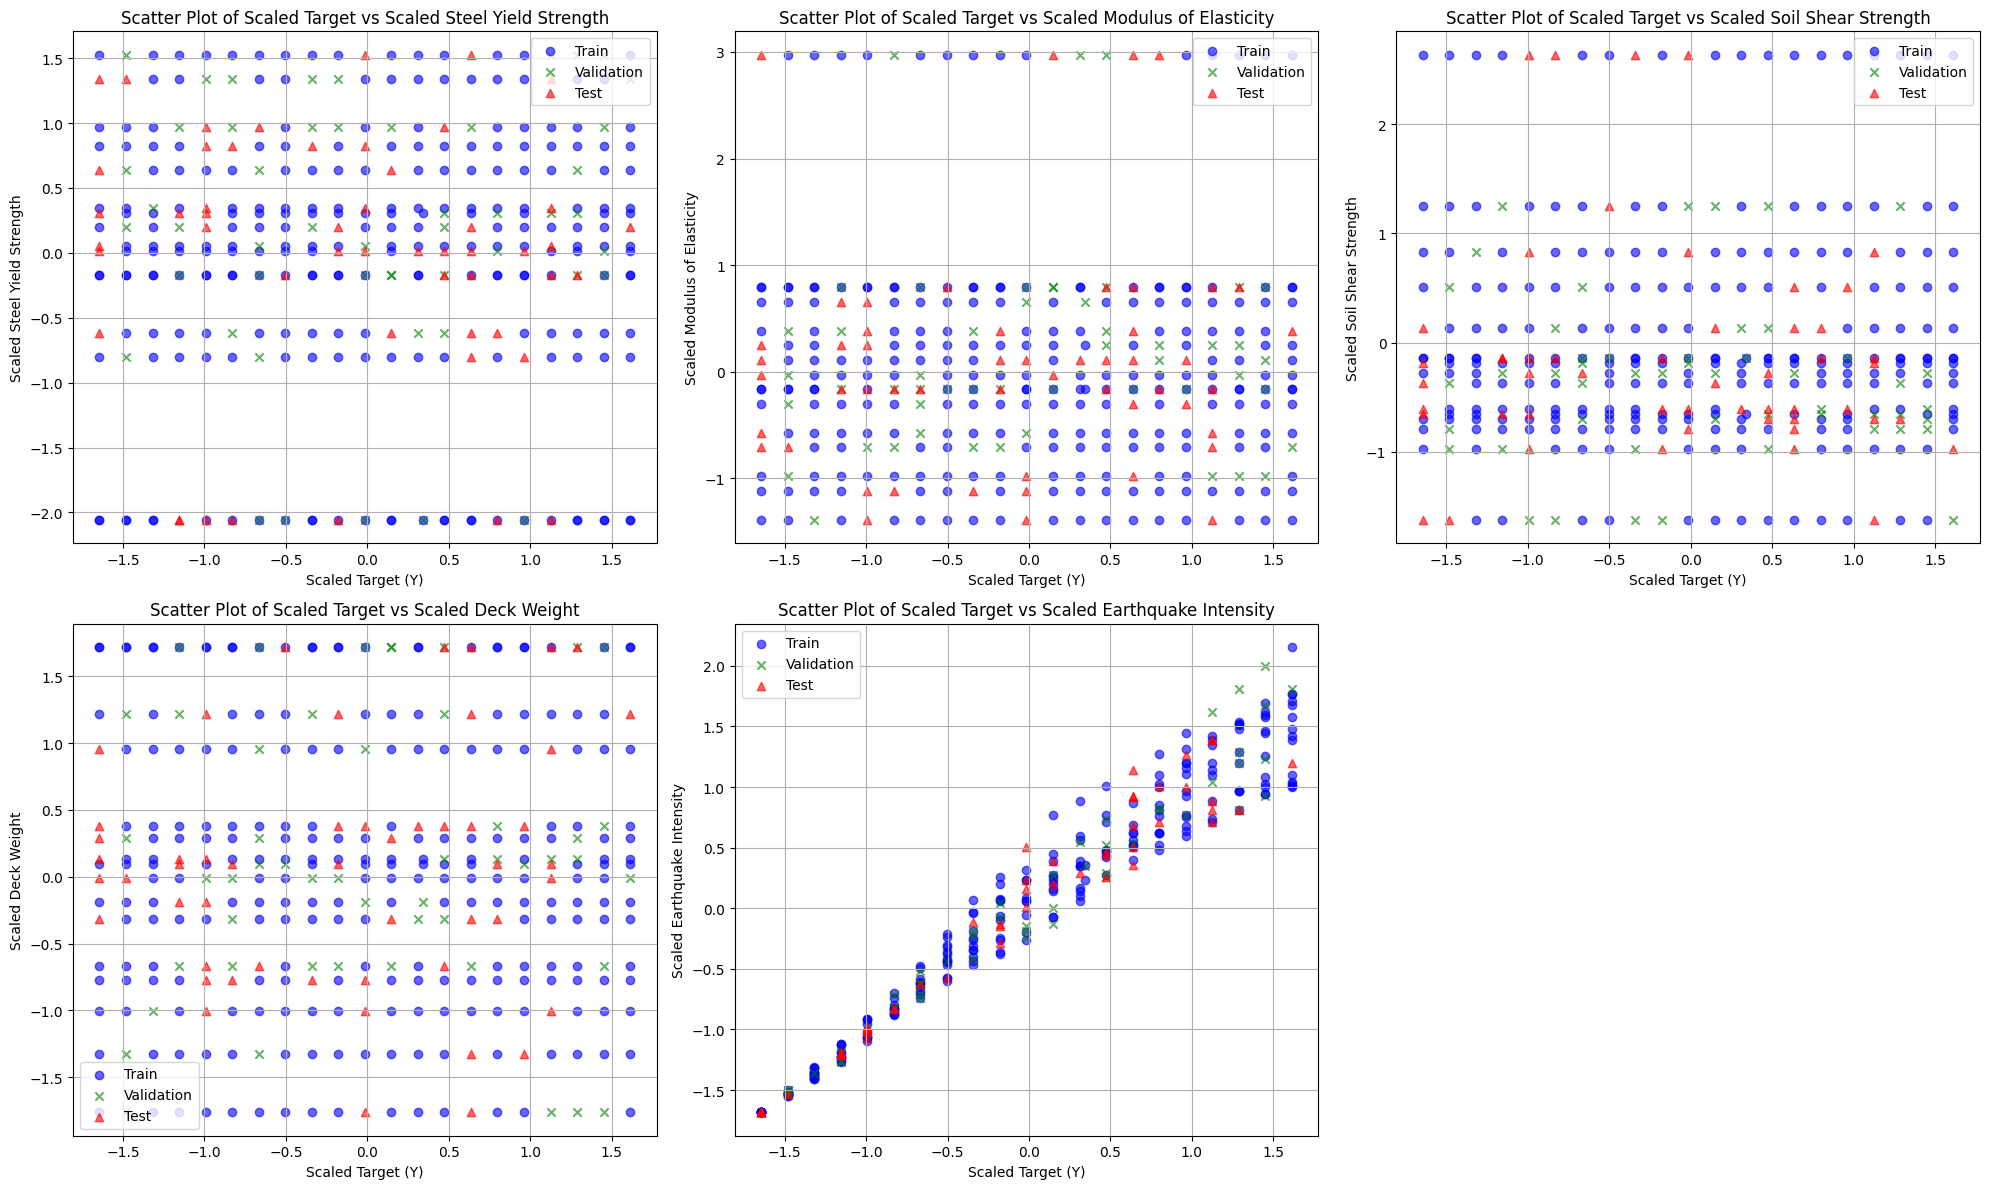

In [ ]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train)
X_val_scaled = scaler_X.transform(X_val)
y_val_scaled = scaler_y.transform(y_val)
X_test_scaled = scaler_X.transform(X_test)
y_test_scaled = scaler_y.transform(y_test)


# نام ویژگی‌ها برای نمایش در نمودار
feature_names = ['Steel Yield Strength', 'Modulus of Elasticity', 'Soil Shear Strength', 'Deck Weight', 'Earthquake Intensity']

# رنگ‌ها و مارکرهای هر دسته داده
colors = {
    'Train': 'blue',
    'Validation': 'green',
    'Test': 'red'
}
markers = {
    'Train': 'o',
    'Validation': 'x',
    'Test': '^'
}

plt.figure(figsize=(20, 12))

for i in range(5):
    plt.subplot(2, 3, i+1)
    # محور افقی: خروجی استانداردشده
    # محور عمودی: ستون iام ورودی استانداردشده
    plt.scatter(y_train_scaled.ravel(), X_train_scaled[:, i], color=colors['Train'], marker=markers['Train'], label='Train', alpha=0.6)
    plt.scatter(y_val_scaled.ravel(), X_val_scaled[:, i], color=colors['Validation'], marker=markers['Validation'], label='Validation', alpha=0.6)
    plt.scatter(y_test_scaled.ravel(), X_test_scaled[:, i], color=colors['Test'], marker=markers['Test'], label='Test', alpha=0.6)
    plt.xlabel('Scaled Target (Y)')
    plt.ylabel(f'Scaled {feature_names[i]}')
    plt.title(f'Scatter Plot of Scaled Target vs Scaled {feature_names[i]}')
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

تعریف تابع زیان سفارشی برای شبکه عصبی با محدودیت‌های فیزیکی خروجی

In [ ]:
lower_bound_scaled = scaler_y.transform(np.array([[0.0]]))[0][0]
upper_bound_scaled = scaler_y.transform(np.array([[20.0]]))[0][0]

def custom_loss(y_true, y_pred):
    mse = tf.reduce_mean(tf.square(y_true - y_pred))
    penalty_lower = tf.reduce_mean(tf.square(tf.minimum(y_pred - lower_bound_scaled, 0.0)))
    penalty_upper = tf.reduce_mean(tf.square(tf.maximum(y_pred - upper_bound_scaled, 0.0)))
    penalty = penalty_lower + penalty_upper
    return mse + 1000.0 * penalty


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 395.9/395.9 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 16.7 MB/s eta 0:00:00


In [ ]:
import optuna
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler

# Assume custom_loss is defined elsewhere
# custom_loss = ...

def create_model(trial):
    # Suggest hyperparameters to tune
    n_units1 = trial.suggest_int('n_units1', 16, 128)
    n_units2 = trial.suggest_int('n_units2', 8, 64)
    learning_rate = trial.suggest_float('learning_rate', 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [8, 16, 32, 64])

    model = Sequential([
        Dense(n_units1, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dense(n_units2, activation='relu'),
        Dense(1, activation='linear')
    ])

    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss=custom_loss, metrics=['mae'])

    return model, batch_size

def scheduler(epoch, lr):
    decay_rate = 0.5
    decay_step = 50
    if epoch != 0 and epoch % decay_step == 0:
        new_lr = lr * decay_rate
        print(f"Epoch {epoch}: reducing learning rate to {new_lr:.6f}")
        return new_lr
    return lr

def objective(trial):
    model, batch_size = create_model(trial)

    early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
    lr_scheduler = LearningRateScheduler(scheduler, verbose=1)

    history = model.fit(
        X_train_scaled, y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=250,
        batch_size=batch_size,
        callbacks=[early_stop, lr_scheduler],
        verbose=0
    )

    val_loss = min(history.history['val_loss'])
    return val_loss

# Create study and optimize
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50)

# Print the best hyperparameters found
print("Best hyperparameters:", study.best_params)

# Train final model with best hyperparameters
best_params = study.best_params
final_model = Sequential([
    Dense(best_params['n_units1'], activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(best_params['n_units2'], activation='relu'),
    Dense(1, activation='linear')
])
final_optimizer = Adam(learning_rate=best_params['learning_rate'])
final_model.compile(optimizer=final_optimizer, loss=custom_loss, metrics=['mae'])

early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
lr_scheduler = LearningRateScheduler(scheduler, verbose=1)

final_model.fit(
    X_train_scaled, y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=250,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)


[I 2025-06-22 13:36:37,228] A new study created in memory with name: no-name-764b71a5-25e0-4504-a2b0-a241ec3a27de



Epoch 1: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 2: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 3: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 4: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 5: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 6: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 7: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 8: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 9: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 10: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 11: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 12: LearningRateScheduler setting learning rate to 0.0038816595915704966.

Epoch 13: LearningRateScheduler sett

[I 2025-06-22 13:37:13,165] Trial 0 finished with value: 0.0036152242682874203 and parameters: {'n_units1': 120, 'n_units2': 27, 'learning_rate': 0.0038816596990605, 'batch_size': 32}. Best is trial 0 with value: 0.0036152242682874203.



Epoch 1: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 2: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 3: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 4: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 5: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 6: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 7: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 8: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 9: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 10: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 11: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 12: LearningRateScheduler setting learning rate to 2.4119131921906956e-05.

Epoch 13: LearningRateSc

[I 2025-06-22 13:37:49,183] Trial 1 finished with value: 0.8460709452629089 and parameters: {'n_units1': 77, 'n_units2': 15, 'learning_rate': 2.4119132306333757e-05, 'batch_size': 64}. Best is trial 0 with value: 0.0036152242682874203.


...


Epoch 1: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 2: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 3: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 4: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 5: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 6: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 7: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 8: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 9: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 10: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 11: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 12: LearningRateScheduler setting learning rate to 0.002305889269337058.

Epoch 13: LearningRateScheduler setting learning

[I 2025-06-22 14:02:10,559] Trial 48 finished with value: 0.004812899045646191 and parameters: {'n_units1': 127, 'n_units2': 61, 'learning_rate': 0.002305889338293453, 'batch_size': 32}. Best is trial 45 with value: 0.0033462506253272295.



Epoch 1: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 2: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 3: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 4: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 5: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 6: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 7: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 8: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 9: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 10: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 11: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 12: LearningRateScheduler setting learning rate to 0.007375637535005808.

Epoch 13: LearningRateScheduler setting learning

[I 2025-06-22 14:02:39,526] Trial 49 finished with value: 0.004451485350728035 and parameters: {'n_units1': 110, 'n_units2': 51, 'learning_rate': 0.007375637722054219, 'batch_size': 16}. Best is trial 45 with value: 0.0033462506253272295.


Best hyperparameters: {'n_units1': 120, 'n_units2': 48, 'learning_rate': 0.0072131831520375845, 'batch_size': 32}

Epoch 1: LearningRateScheduler setting learning rate to 0.0072131832130253315.
Epoch 1/250
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.7679 - mae: 0.5504 - val_loss: 0.1172 - val_mae: 0.2554 - learning_rate: 0.0072

Epoch 2: LearningRateScheduler setting learning rate to 0.0072131832130253315.
Epoch 2/250
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.6311 - mae: 0.3298 - val_loss: 0.3605 - val_mae: 0.4587 - learning_rate: 0.0072

Epoch 3: LearningRateScheduler setting learning rate to 0.0072131832130253315.
Epoch 3/250
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.3568 - mae: 0.4366 - val_loss: 0.2450 - val_mae: 0.3222 - learning_rate: 0.0072

Epoch 4: LearningRateScheduler setting learning rate to 0.0072131832130253315.
Epoch 4/250
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.2567 - mae: 0.3488 - val_loss: 0.1408 - val_mae: 0.2642 - learning_rate: 0.0072

Epoch

ترسیم معماری شبکه عصبی

/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


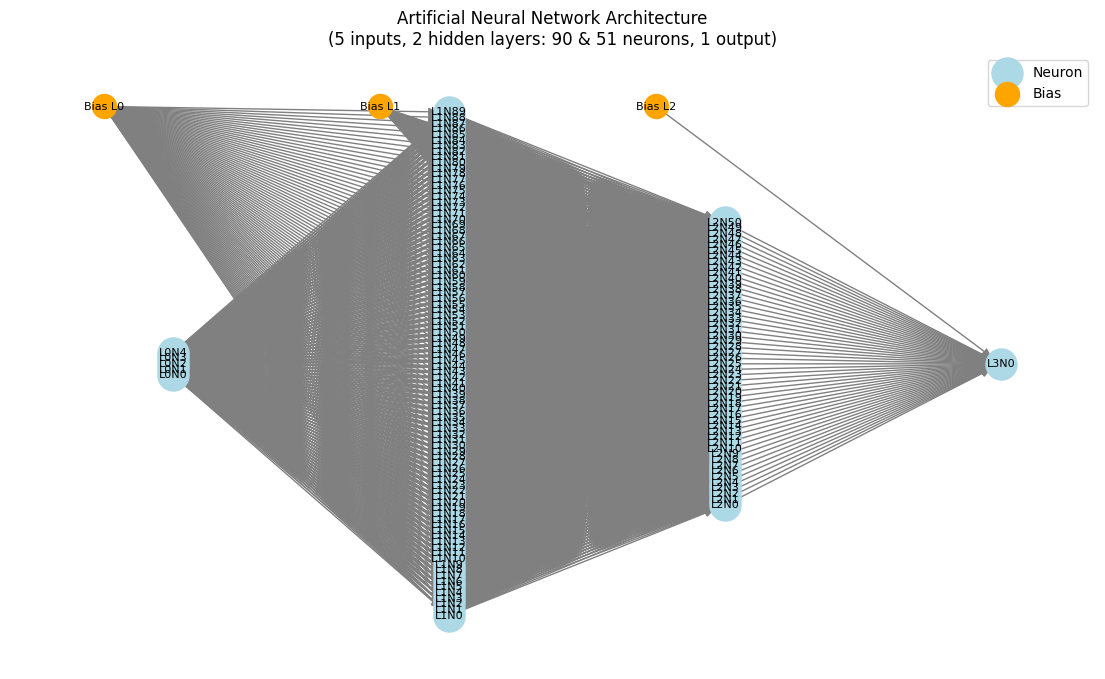

In [ ]:

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

def draw_ann(input_size=5, hidden_layers=[90,51], output_size=1):
    G = nx.DiGraph()

    # تعیین موقعیت نورون‌ها در هر لایه
    layers = [input_size] + hidden_layers + [output_size]
    pos = {}
    layer_x = 0
    layer_sep_x = 2
    max_layer_size = max(layers)

    # موقعیت‌دهی نورون‌ها
    for layer_idx, layer_size in enumerate(layers):
        layer_y_start = (max_layer_size - layer_size) / 2
        for neuron_idx in range(layer_size):
            pos[(layer_idx, neuron_idx)] = (layer_x, layer_y_start + neuron_idx)
        layer_x += layer_sep_x

    # اضافه کردن نورون‌ها به گراف
    for layer_idx, layer_size in enumerate(layers):
        for neuron_idx in range(layer_size):
            G.add_node((layer_idx, neuron_idx))

    # اضافه کردن بایاس‌ها به عنوان نورون‌های جداگانه کنار هر لایه به جز لایه خروجی
    bias_offset = 0.5
    for layer_idx, layer_size in enumerate(layers[:-1]):
        bias_node = ('b', layer_idx)
        # بایاس را بالاتر از نورون‌ها قرار می‌دهیم
        pos[bias_node] = (layer_idx * layer_sep_x - bias_offset, max_layer_size)
        G.add_node(bias_node)
        # اتصال بایاس به همه نورون‌های لایه بعدی
        next_layer_size = layers[layer_idx + 1]
        for neuron_idx in range(next_layer_size):
            G.add_edge(bias_node, (layer_idx + 1, neuron_idx))

    # اضافه کردن اتصالات بین نورون‌های لایه‌ها
    for layer_idx in range(len(layers) - 1):
        for src in range(layers[layer_idx]):
            for dst in range(layers[layer_idx + 1]):
                G.add_edge((layer_idx, src), (layer_idx + 1, dst))

    # رسم گراف
    plt.figure(figsize=(14, 8))
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G.nodes if isinstance(n[0], int)],
                           node_color='lightblue', node_size=500, label='Neuron')
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G.nodes if isinstance(n[0], str)],
                           node_color='orange', node_size=300, label='Bias')
    nx.draw_networkx_edges(G, pos, arrowstyle='-|>', arrowsize=12, edge_color='gray')

    # برچسب نورون‌ها (اختیاری)
    labels = {}
    for node in G.nodes:
        if isinstance(node[0], int):
            labels[node] = f"L{node[0]}N{node[1]}"
        else:
            labels[node] = f"Bias L{node[1]}"
    nx.draw_networkx_labels(G, pos, labels, font_size=8)

    plt.title('Artificial Neural Network Architecture\n(5 inputs, 2 hidden layers: 90 & 51 neurons, 1 output)')
    plt.axis('off')
    plt.legend(scatterpoints=1)
    plt.show()

# فراخوانی تابع رسم
draw_ann()


10- تحلیل حساسیت خروجی به متغیرهای ورودی

Input Feature Sensitivities (average absolute gradient):
Steel Yield Strength: 0.1228
Modulus of Elasticity: 0.0852
Soil Shear Strength: 0.0672
Roof Live Load: 0.1545
Earthquake Intensity: 1.0527


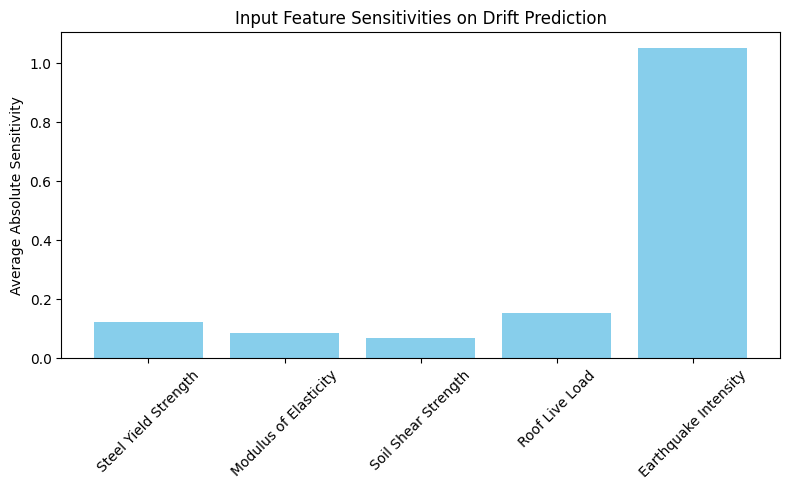

In [ ]:
# Sensitivity analysis using gradients
def compute_sensitivities(model, X_sample):
    X_tensor = tf.convert_to_tensor(X_sample, dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(X_tensor)
        predictions = final_model(X_tensor)
    grads = tape.gradient(predictions, X_tensor)  # shape: (batch_size, num_features)
    sensitivities = tf.reduce_mean(tf.abs(grads), axis=0)  # average sensitivity per input feature
    return sensitivities.numpy()

sensitivities = compute_sensitivities(final_model, X_test_scaled)

# 12. Print sensitivities
feature_names = ['Steel Yield Strength', 'Modulus of Elasticity', 'Soil Shear Strength', 'Deck Weight', 'Earthquake Intensity']
print("Input Feature Sensitivities (average absolute gradient):")
for name, sens in zip(feature_names, sensitivities):
    print(f"{name}: {sens:.4f}")

# 13. Plot sensitivities
plt.figure(figsize=(8,5))
plt.bar(feature_names, sensitivities, color='skyblue')
plt.ylabel('Average Absolute Sensitivity')
plt.title('Input Feature Sensitivities on Drift Prediction')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

تعریف سایر مدل‌های یادگیری ماشین

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000040 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 131
[LightGBM] [Info] Number of data points in the train set: 235, number of used features: 5
[LightGBM] [Info] Start training from score 5.047660
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: divide by zero encountered in divide
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: divide by zero encountered in divide
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: divide by zero encountered in divide
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: divide by zero encountered in divide
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: invalid value encountered in divide
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: divide by zero encountered in divide
  mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
/tmp/ipython-input-18-3677107963.py:38: RuntimeWarning: divide by zero encountered in div

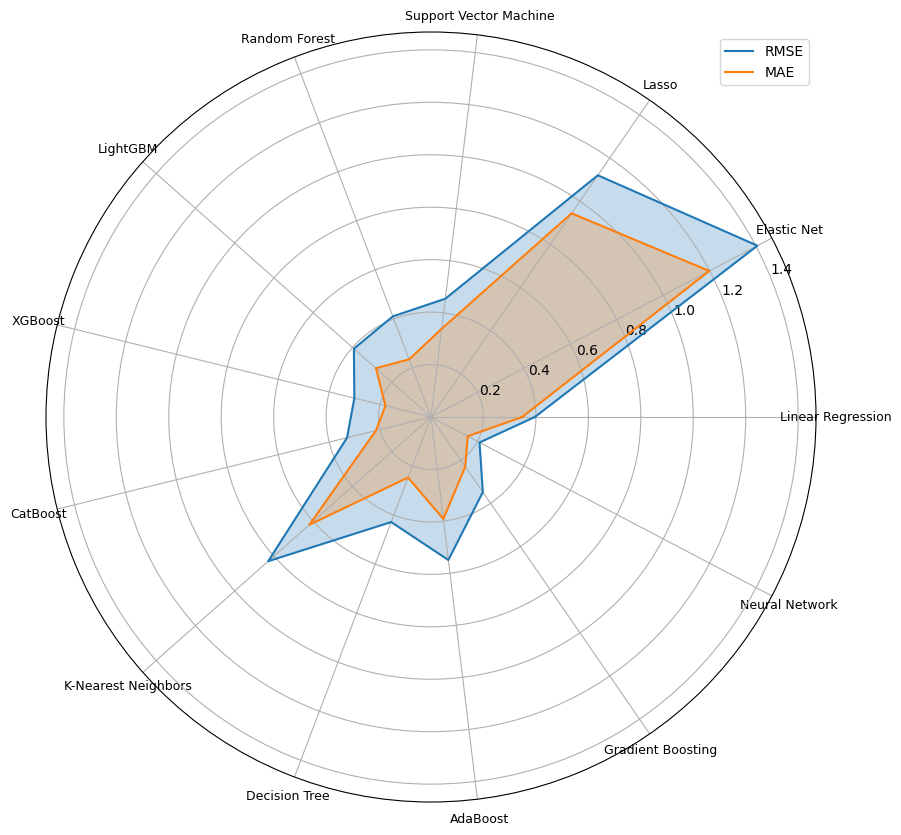

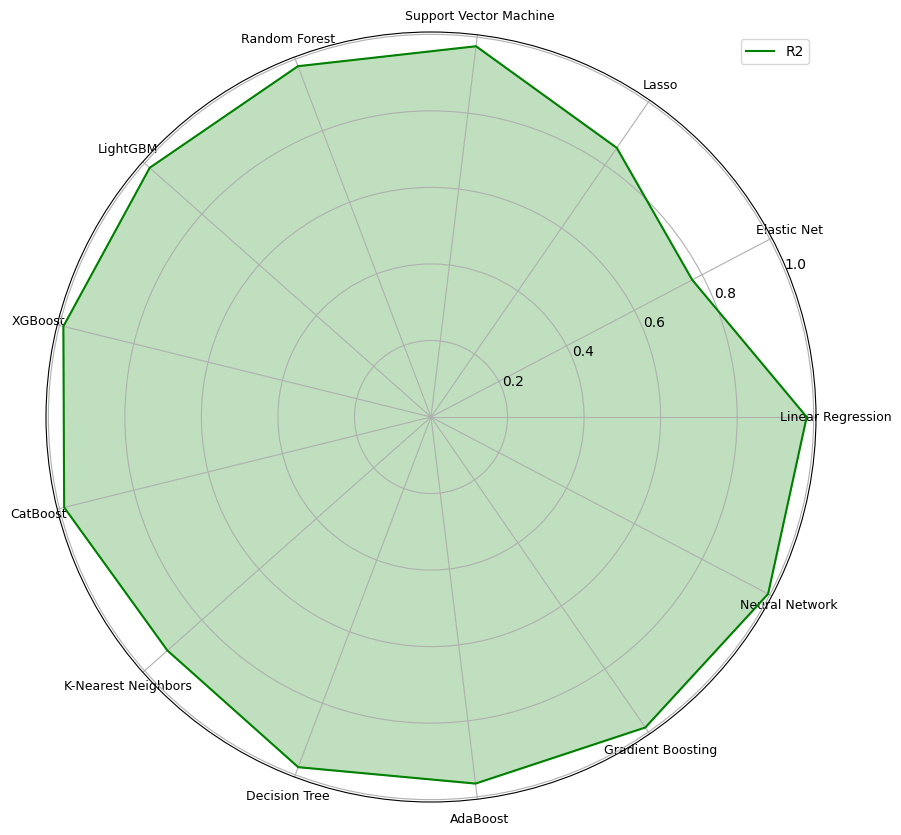

In [ ]:
models = {
    'Linear Regression': LinearRegression(),
    'Elastic Net': ElasticNet(),
    'Lasso': Lasso(),
    'Support Vector Machine': SVR(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'LightGBM': lgb.LGBMRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42, verbosity=0),
    'CatBoost': CatBoostRegressor(random_state=42, verbose=0),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}
# آموزش و پیش‌بینی مدل‌ها
results = {}
for name, model in models.items():
    if name in ['Support Vector Machine', 'Elastic Net', 'Lasso', 'Linear Regression', 'K-Nearest Neighbors']:
        model.fit(X_train_scaled, y_train.ravel())
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train.ravel())
        y_pred = model.predict(X_test)
    results[name] = y_pred

# پیش‌بینی مدل ANN
y_pred_ann_scaled = final_model.predict(X_test_scaled)
y_pred_ann = scaler_y.inverse_transform(y_pred_ann_scaled).ravel()
results['Neural Network'] = y_pred_ann

y_true = y_test.ravel()
# محاسبه معیارهای ارزیابی برای هر مدل
def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {'R2': r2, 'MSE': mse, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape}

metrics_all = {name: compute_metrics(y_true, y_pred) for name, y_pred in results.items()}
# نمایش معیارهای مدل‌ها
print("Evaluation metrics for all models:")
for name, met in metrics_all.items():
    print(f"{name}: R2={met['R2']:.4f}, RMSE={met['RMSE']:.4f}, MAE={met['MAE']:.4f}")
# رسم نمودارهای راداری RMSE و MAE (مقادیر اصلی)
labels_rmse_mae = ['RMSE', 'MAE']
num_models = len(results)
angles = np.linspace(0, 2 * np.pi, num_models, endpoint=False).tolist()
angles += angles[:1]

plt.figure(figsize=(10,10))
ax = plt.subplot(111, polar=True)
for metric in labels_rmse_mae:
    values = [metrics_all[name][metric] for name in results.keys()]
    values.append(values[0])
    ax.plot(angles, values, label=metric)
    ax.fill(angles, values, alpha=0.25)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(list(results.keys()), fontsize=9)
ax.set_title('')
ax.legend()
plt.show()
# رسم نمودار راداری R2
plt.figure(figsize=(10,10))
ax = plt.subplot(111, polar=True)
values = [metrics_all[name]['R2'] for name in results.keys()]
values.append(values[0])
ax.plot(angles, values, label='R2', color='green')
ax.fill(angles, values, alpha=0.25, color='green')
ax.set_xticks(angles[:-1])
ax.set_xticklabels(list(results.keys()), fontsize=9)
ax.set_title('')
ax.legend()
plt.show()


حساسیت به سایز ورودی

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor  # Example model

# Assume X (features) and y (target) are already loaded

# Define a range of dataset sizes to test
dataset_sizes = [0.1, 0.3, 0.5, 0.7, 0.9]  # Fractions of the full dataset

# Store results for each model
results = {}

# Define models to evaluate
models = {
    'Linear Regression': LinearRegression(),
    'Elastic Net': ElasticNet(),
    'Lasso': Lasso(),
    'Support Vector Machine': SVR(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'LightGBM': lgb.LGBMRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(random_state=42, verbosity=0),
    'CatBoost': CatBoostRegressor(random_state=42, verbose=0),
    'K-Nearest Neighbors': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'ANN': MLPRegressor(random_state=42, max_iter=300)  # Example ANN
    # Add other models here
}

for model_name, model in models.items():
    results[model_name] = []
    for size in dataset_sizes:
        # Reduce dataset size
        X_train_subset, _, y_train_subset, _ = train_test_split(
            X_train, y_train, train_size=size, random_state=42
        )

        # Train model
        model.fit(X_train_subset, y_train_subset)

        # Make predictions on the validation set
        y_pred = model.predict(X_val)

        # Evaluate performance
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        r2 = r2_score(y_val, y_pred)
        results[model_name].append((rmse, r2))

    # Plotting the results for each model
    rmse_values = [result[0] for result in results[model_name]]
    r2_values = [result[1] for result in results[model_name]]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    color = 'tab:red'
    ax1.set_xlabel('Fraction of Training Data')
    ax1.set_ylabel('RMSE', color=color)
    ax1.plot(dataset_sizes, rmse_values, color=color, marker='o')
    ax1.tick_params(axis='y', labelcolor=color)

    ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis

    color = 'tab:blue'
    ax2.set_ylabel('R2 Score', color=color)  # we already handled the x-label with ax1
    ax2.plot(dataset_sizes, r2_values, color=color, marker='x')
    ax2.tick_params(axis='y', labelcolor=color)

    fig.tight_layout()  # otherwise the right y-label is slightly clipped
    plt.title(f'Dataset Size Sensitivity - {model_name}')
    plt.show()


NameError: name 'LinearRegression' is not defined

In [ ]:
# رتبه‌بندی مدل‌ها بر اساس R2 و RMSE
sorted_r2 = sorted(metrics_all.items(), key=lambda x: x[1]['R2'], reverse=True)
sorted_rmse = sorted(metrics_all.items(), key=lambda x: x[1]['RMSE'])

print("Ranking by R2 (descending):")
for i, (name, met) in enumerate(sorted_r2, 1):
    print(f"{i}. {name}: R2={met['R2']:.4f}")

print("\nRanking by RMSE (ascending):")
for i, (name, met) in enumerate(sorted_rmse, 1):
    print(f"{i}. {name}: RMSE={met['RMSE']:.4f}")

# انتخاب مدل توسط کاربر برای ادامه پردازش
print("\nPlease select a model for further processing by typing its name exactly as shown above:")
selected_model_name = input()
while selected_model_name not in results.keys():
    print("Invalid selection. Please enter a valid model name:")
    selected_model_name = input()
print(f"You selected: {selected_model_name}")

# رسم نمودار خطاهای آموزش و اعتبارسنجی برای ANN (در صورت انتخاب)
if selected_model_name == 'Neural Network':
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(history.history['loss'], label='Train Loss (Custom)')
    plt.plot(history.history['val_loss'], label='Validation Loss (Custom)')
    plt.title('Training and Validation Loss (MSE-based)')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(history.history['mae'], label='Train MAE')
    plt.plot(history.history['val_mae'], label='Validation MAE')
    plt.title('Training and Validation MAE')
    plt.xlabel('Epoch')
    plt.ylabel('MAE')
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print(f"Training history plots are available only for Neural Network model.")


Ranking by R2 (descending):
1. Neural Network: R2=0.9949
2. XGBoost: R2=0.9895
3. CatBoost: R2=0.9874
4. Gradient Boosting: R2=0.9860
5. LightGBM: R2=0.9821
6. Linear Regression: R2=0.9818
7. Random Forest: R2=0.9805
8. Decision Tree: R2=0.9787
9. Support Vector Machine: R2=0.9761
10. AdaBoost: R2=0.9650
11. K-Nearest Neighbors: R2=0.9203
12. Lasso: R2=0.8546
13. Elastic Net: R2=0.7710

Ranking by RMSE (ascending):
1. Neural Network: RMSE=0.2090
2. XGBoost: RMSE=0.3010
3. CatBoost: RMSE=0.3297
4. Gradient Boosting: RMSE=0.3481
5. LightGBM: RMSE=0.3928
6. Linear Regression: RMSE=0.3961
7. Random Forest: RMSE=0.4104
8. Decision Tree: RMSE=0.4284
9. Support Vector Machine: RMSE=0.4544
10. AdaBoost: RMSE=0.5494
11. K-Nearest Neighbors: RMSE=0.8294
12. Lasso: RMSE=1.1200
13. Elastic Net: RMSE=1.4057

Please select a model for further processing by typing its name exactly as shown above:


KeyboardInterrupt: Interrupted by user

پیش‌بینی ورودی جدید با مدل انتخابی

In [ ]:
# پیش‌بینی ورودی جدید با مدل انتخابی
new_input = np.array([[235, 2, 60, 1000, 1]])
new_input = clip_inputs(new_input)

# Check physical constraint: if 5th column == 0, output = 0
if new_input[0, 4] == 0:
    pred = 0.0
else:
    if selected_model_name == 'Neural Network':
        new_input_scaled = scaler_X.transform(new_input)
        pred_scaled = ann_model.predict(new_input_scaled)
        pred = scaler_y.inverse_transform(pred_scaled)[0][0]
    else:
        model = models[selected_model_name]
        if selected_model_name in ['Support Vector Machine', 'Elastic Net', 'Lasso', 'Linear Regression', 'K-Nearest Neighbors']:
            new_input_scaled = scaler_X.transform(new_input)
            pred = model.predict(new_input_scaled)[0]
        else:
            pred = model.predict(new_input)[0]

print(f"Prediction for new input by {selected_model_name}: {pred:.6f}")




In [ ]:
# Define the fixed input values except IM
base_input = [	284	,	1.97	,	127.0	,	1004	]



# Define the IM values from 0 to 2 with 0.2 increments
im_values = np.arange(0, 2.61, 0.2)
# Prepare an array to store predictions
predictions = []
for im in im_values:
    # Construct the input array for this IM
    new_input = np.array([base_input + [im]])
    new_input = clip_inputs(new_input)
    # Physical constraint: if IM == 0, output = 0
    if new_input[0, 4] == 0:
        pred = 0.0
    else:
        if selected_model_name == 'Neural Network':
            new_input_scaled = scaler_X.transform(new_input)
            pred_scaled = ann_model.predict(new_input_scaled)
            pred = scaler_y.inverse_transform(pred_scaled)[0][0]
        else:
            model = models[selected_model_name]
            if selected_model_name in ['Support Vector Machine', 'Elastic Net', 'Lasso', 'Linear Regression', 'K-Nearest Neighbors']:
                new_input_scaled = scaler_X.transform(new_input)
                pred = model.predict(new_input_scaled)[0]
            else:
                pred = model.predict(new_input)[0]
    predictions.append((im, pred))
# Print the results
for im, pred in predictions:
    print(f"IM: {im:.1f}, Prediction: {pred:.6f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
IM: 0.0, Prediction: 0.000000
IM: 0.2, Prediction: 1.219272
IM: 0.4, Prediction: 2.157270
IM: 0.6, Prediction: 3.159433
IM: 0.8, Prediction: 4.432990
IM: 1.0, Prediction: 5.722555
IM: 1.2, Prediction: 7.020706
IM: 1.4, Prediction: 8.337785
IM: 1.6, Prediction: 9.663367
IM: 1.8, Prediction: 10.960078
IM: 2.0, Prediction: 12.242152
IM: 2.2, Prediction: 13.561697
IM: 2.4, Prediction: 14.766173
IM: 2.6, Prediction: 15.932947
